# Phase 6 (Gemini): RAG arm (policy text retrieved at each write step)

**Goal:** an ablation for RQ2. Is it the *graph* that helps semi-deep, or just showing the agent some rules right before it acts? Semi-deep (08) and this arm are the same except for where the rules come from.

| | semi-deep (08) | RAG (14) |
|---|---|---|
| when | before each write tool call | same |
| check prompt | same | same (only "from the policy graph" → "retrieved from the policy text") |
| rules come from | the policy graph, by action name | `wiki.md` bullets, by vector similarity to the pending call |
| amount of text | the graph rules of that action | about the same number of characters |

**How it works:** `wiki.md` is split into its 26 policy bullets (+ 2 intro lines). Each bullet is tagged with its id (G1–G5, D1–D3, B1–B5, M1–M6, C1–C4, R1–R3), the same ids the graph uses. The bullets are embedded once with `all-MiniLM-L6-v2` (free, runs on CPU). Before a write call, the query is the tool name + its arguments. The most similar bullets are shown until they reach semi-deep's character budget for that tool. Every retrieval is logged in `trial_k/rag.jsonl` with the bullet ids it got and the ids the graph would have given (recall).

**Run first:** 05G, 06G, 04, 08 (they write `settings_gemini.py`, `gemini_run.py`, `policy_checker.py`, `violations.py`, `graph_text.py`, `passk.py`). This notebook writes `rag_text.py` and a new `kil_run.py`. Semi-deep and shallow still get exactly the same prompts as before (checked).

**Runtime:** CPU only. **Model:** `gemini-3.1-flash-lite` (paid Gemini API, `settings_gemini.py`). **Cost:** about $22 (token estimate). **Time:** about 4 hours (229 min).

**Run:** 50 tasks × 8 trials into `results_gemini_rag/trial_1..8/`. Safe to stop: finished tasks are skipped.

**Compared with:** baseline (05G), validator (06G), semi-deep (08), on all 50 tasks and the 42 clean tasks.

**Result:** same pass^k as semi-deep, but 28 violations vs 2. RAG misses rules (recall 71%), and missed rules become broken rules. See the Summary at the end.

| cell | what | why |
|---|---|---|
| 1–2 | mount Drive, install | results must survive a runtime reset; tau-bench + embedding library |
| 3 | settings + API check | same frozen settings as every Gemini arm; fail early if the key or model is wrong |
| 4–5 | save `rag_text.py`, `kil_run.py` | the RAG retriever and the hook that runs it before each write call |
| 6 | retrieval preview | see what RAG will show, before paying for the run |
| 7 | run | 400 dialogues |
| 8 | progress + cost | see unfinished tasks, API errors and money spent |
| 9–13 | results | pass^k, paired tests, violations, decisions, retrieval recall |

In [2]:
# Why: results and code live on Google Drive, so they survive when the Colab runtime resets.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Why: tau-bench runs the dialogues; sentence-transformers embeds the policy bullets for RAG.
# (The red protobuf warnings come from Colab's Google Cloud packages; they do not affect this notebook.)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
!pip install -q mcp sentence-transformers
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-spanner 3.71.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-storage-control 1.17.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-language 2.22.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-translate 3.28.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires p

In [4]:
# Why: every Gemini arm must use the same frozen settings (settings_gemini.py), or the comparison
# is not fair. This cell loads them, gets the API key from Colab Secrets, and makes one test call,
# so a wrong key or model fails here and not in the middle of the night run.
import os, sys, re, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"   # every later cell uses this path
sys.path.insert(0, ROOT)
os.chdir(ROOT)
need = ["settings_gemini.py", "gemini_run.py", "policy_checker.py", "violations.py",
        "airline_policy_graph.json", "passk.py", "graph_text.py"]
missing = [f for f in need if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 05G, 06G, 04 and 08 first"

importlib.invalidate_caches()
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import *
warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)   # hide litellm's long warnings

def short_error(e):
    # keep only the API's own message, one line
    m = re.search(r'"message":\s*"([^"]+)"', str(e))
    return (m.group(1) if m else str(e).splitlines()[0])[:200]

def set_token():
    # the key comes from Colab Secrets and is never printed or saved in a file
    if BACKEND == "colab":
        from google.colab import ai     # the Colab token can expire, so get a fresh one
        os.environ["COLAB_PROXY_BASE"] = f"{ai._get_model_proxy_host()}/models/openapi"
        os.environ["COLAB_PROXY_KEY"] = ai._get_model_proxy_token()
    else:
        from google.colab import userdata
        os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
set_token()

def show(df, index=False):
    # one table style for the whole notebook
    st = df.style.set_properties(**{"text-align": "left"})
    display(st if index else st.hide(axis="index"))

# settings as a narrow two-column table
S = {k: str(v) for k, v in vars(settings_gemini).items() if k.isupper()}
keys = list(S); half = (len(keys) + 1) // 2
left, right = keys[:half], keys[half:] + [""] * (2 * half - len(keys))
show(pd.DataFrame({"setting": left, "value": [S[k] for k in left],
                   "setting ": right, "value ": [S.get(k, "") for k in right]}))

# one test call with a tool, like the agent will make
import litellm
litellm.suppress_debug_info = True
tools = [{"type": "function", "function": {
    "name": "get_reservation", "description": "Look up a reservation",
    "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}},
                   "required": ["reservation_id"]}}}]
if BACKEND == "colab":
    kw = dict(model=PROXY_PREFIX + MODEL, custom_llm_provider="openai",
              api_base=os.environ["COLAB_PROXY_BASE"], api_key=os.environ["COLAB_PROXY_KEY"])
else:
    kw = dict(model=MODEL, custom_llm_provider="gemini", api_key=os.environ["GEMINI_API_KEY"])
try:
    r = litellm.completion(**kw, temperature=0.0, tools=tools,
                           messages=[{"role": "user", "content": "Look up reservation ABC123."}])
    ok = bool(r.choices[0].message.tool_calls)
    print(f"{'✅ tool call works' if ok else '❌ no tool call'} | model {MODEL}")
except Exception as e:
    print(f"❌ {type(e).__name__}: {short_error(e)}")
    print("Fix MODEL in settings_gemini.py (05G, cell 3), run that cell in 05G, then this cell again.")

setting,value,setting,value
BACKEND,apikey,CONCURRENCY,4
MODEL,gemini-3.1-flash-lite,NUM_RETRIES,6
PRICE_IN,0.25,CALL_TIMEOUT,600
PRICE_OUT,1.5,ENV,airline
PROXY_PREFIX,google/,N_TASKS,50
TEMPERATURE,0.0,N_TRIALS,8
USER_TEMPERATURE,1.0,,


✅ tool call works | model gemini-3.1-flash-lite


In [5]:
# Why: the RAG arm needs a retriever over the policy TEXT, to compare with semi-deep's graph.
# The file's code is in CODE below; this cell saves it into the repo and shows a one-row table.
CODE = r'''# Vector RAG over the policy TEXT (wiki.md), for the RAG arm (14).
# Same moment and same prompt as semi-deep (08); only the source of the rules changes:
#   semi-deep: the rules of the action, taken from the policy graph (by action name)
#   RAG:       the wiki.md bullets most similar to the pending tool call (by embedding)
# Fair budget: for each tool, RAG gets about as many characters as semi-deep shows for it.
import os
import re

import numpy as np

EMBED_MODEL = os.environ.get("RAG_EMBED_MODEL", "sentence-transformers/all-MiniLM-L6-v2")


def chunks(wiki):
    """One chunk per policy bullet (sub-bullets stay with their bullet), with its section title."""
    out, section, cur = [], "Policy", None
    for line in wiki.splitlines():
        if line.startswith("#"):
            if cur: out.append(cur); cur = None
            section = line.lstrip("#").strip()
        elif line.startswith("- "):
            if cur: out.append(cur)
            cur = {"section": section, "text": line[2:].strip(), "bullet": True}
        elif line.startswith("  ") and cur and line.strip():
            cur["text"] += "\n" + line.strip()
        elif not line.strip():
            continue
        else:  # a plain sentence outside a bullet (e.g. the intro)
            if cur: out.append(cur); cur = None
            out.append({"section": section, "text": line.strip()})
    if cur: out.append(cur)
    # bullet ids as in the policy graph: G1-G5, D1-D3, B1-B5, M1-M6, C1-C4, R1-R3
    letter = {"Airline Agent Policy": "G", "Domain Basic": "D", "Book flight": "B",
              "Modify flight": "M", "Cancel flight": "C", "Refund": "R"}
    seen = {}
    for i, c in enumerate(out):
        c["id"] = i
        c["doc"] = f"{c['section']}: {c['text']}"
        c["source"] = None
        if c.pop("bullet", False) and c["section"] in letter:
            L = letter[c["section"]]; seen[L] = seen.get(L, 0) + 1
            c["source"] = f"{L}{seen[L]}"
    return out


# one tool can be two graph actions (change flights, or only the cabin)
GRAPH_ACTIONS = {"update_reservation_flights": ["update_reservation_flights", "upgrade_cabin"]}


def graph_rules(G, tool):
    """The rule text semi-deep shows for this tool (also RAG's character budget)."""
    import graph_text as gt
    names = GRAPH_ACTIONS.get(tool, [tool])
    head = "whichever of these fits the call" if len(names) > 1 else ""
    return (head + "\n\n" if head else "") + "\n\n".join(gt.action_text(G, n) for n in names)


def query_text(tool, arguments):
    # what the agent is about to do, in words: "cancel reservation reason: change_of_plan ..."
    return f"{tool.replace('_', ' ')} {arguments}"


class Retriever:
    def __init__(self, wiki, encode=None):
        self.chunks = chunks(wiki)
        if encode is None:
            from sentence_transformers import SentenceTransformer
            m = SentenceTransformer(EMBED_MODEL, device="cpu")
            encode = lambda xs: m.encode(xs, normalize_embeddings=True)
        self.encode = encode
        self.E = np.asarray(encode([c["doc"] for c in self.chunks]))

    def rank(self, query):
        q = np.asarray(self.encode([query]))[0]
        s = self.E @ q
        return [(self.chunks[i], float(s[i])) for i in np.argsort(-s)]

    def retrieve(self, query, budget_chars):
        """Best chunks in order until they reach the budget (the last one may go a bit over,
        so RAG never gets less text than semi-deep)."""
        picked, used = [], 0
        for c, s in self.rank(query):
            if used >= budget_chars:
                break
            picked.append((c, s)); used += len(c["doc"])
        return picked

    def text(self, query, budget_chars):
        return "\n\n".join(f"- [{c['section']}] {c['text']}" for c, _ in self.retrieve(query, budget_chars))


def needed(rules_text):
    """Bullet ids the policy graph uses for this action (from semi-deep's rule text)."""
    return sorted(set(re.findall(r"\[([GDBMCR]\d)", rules_text)))
'''

open(f"{ROOT}/rag_text.py", "w").write(CODE)
show(pd.DataFrame([{"file": "rag_text.py", "lines": CODE.count(chr(10)), "saved": "✅"}]))

file,lines,saved
rag_text.py,94,✅


In [6]:
# Why: one runner for all KiL arms, so shallow, semi-deep and RAG differ only in KIL_MODE.
# The file's code is in CODE below; this cell saves it into the repo and shows a one-row table.
CODE = r'''# KiL arms on Gemini. Same agent, model and settings as 05G (gemini_run.py runs them).
# KIL_MODE picks how the policy graph reaches the agent (no validator in either arm):
#   "shallow"  (07): the whole graph, as text rules, is added to the system prompt once.
#   "semideep" (08): the graph is used step by step. When the agent is about to call a
#                    write tool, the rules for that one action are retrieved from the graph
#                    and shown to it; it must check each rule against the conversation and
#                    the tool results, then either repeat the call or not call it.
#   "rag"      (14): same moment and same check as semi-deep, but the rules come from vector
#                    retrieval over the policy TEXT (wiki.md bullets most similar to the call),
#                    with about the same number of characters as semi-deep shows. This tests
#                    graph retrieval vs plain text retrieval.
import json
import os
import runpy
import sys
import threading

import litellm
import graph_text as gt

MODE = os.environ["KIL_MODE"]
assert MODE in ("shallow", "semideep", "rag"), MODE
G = gt.load()
WRITE_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
               "update_reservation_passengers", "cancel_reservation", "send_certificate"}
CHECK_LOG = os.environ.get("CHECK_LOG", "kil_checks.jsonl")
_lock = threading.Lock()

if MODE == "shallow":
    # the airline env reads WIKI when it is built, so I extend it before run.main()
    import tau_bench.envs.airline.env as airline_env
    airline_env.WIKI = airline_env.WIKI + "\n\n" + gt.full_text(G)

if MODE in ("semideep", "rag"):
    import rag_text as rt   # graph_rules() is the same rule text as before; numpy only, no model

    def rules_for(tool):
        return rt.graph_rules(G, tool)

    if MODE == "rag":
        import tau_bench.envs.airline.env as airline_env
        RET = rt.Retriever(airline_env.WIKI)   # embeds the wiki.md bullets once
        RAG_LOG = os.environ.get("RAG_LOG", "rag_retrieved.jsonl")

        def rag_rules(call):
            name = call.function.name
            q = rt.query_text(name, call.function.arguments)
            with _lock:
                picked = RET.retrieve(q, len(rules_for(name)))   # same budget as semi-deep
                with open(RAG_LOG, "a") as f:
                    f.write(json.dumps({"tool": name, "chunks": [c["id"] for c, _ in picked],
                                        "sources": [c["source"] for c, _ in picked],
                                        "needed": rt.needed(rules_for(name)),
                                        "scores": [round(s, 3) for _, s in picked]}) + "\n")
            return "\n\n".join(f"- [{c['section']}] {c['text']}" for c, _ in picked)

    def check_prompt(call):
        name = call.function.name
        if MODE == "rag":
            src, rules = "retrieved from the policy text", rag_rules(call)
        else:
            src, rules = "from the policy graph", rules_for(name)
        return (
            f"[Policy check before acting] You are about to call {name} with "
            f"{call.function.arguments}. These are the rules for this action, {src}:\n\n"
            f"{rules}\n\n"
            "Go through the rules one by one. For each, say in one short line whether it is met, "
            "not met, or unknown, using only this conversation and the tool results so far. "
            "Then: if every rule is met, make the same tool call again (fix the arguments if needed). "
            "If a rule is not met or unknown, do not call the tool; ask the user or explain the policy.")

    import tau_bench.agents.tool_calling_agent as agent_mod

    def semideep(*args, **kwargs):
        # litellm.completion is looked up at call time, so gemini_run.py's backend
        # and logging (patched later) are used for both calls
        res = litellm.completion(*args, **kwargs)
        msg = res.choices[0].message
        calls = msg.tool_calls or []
        if not calls or calls[0].function.name not in WRITE_TOOLS:
            return res
        first = calls[0]
        kw = dict(kwargs)
        kw["messages"] = list(kwargs["messages"]) + [{"role": "user", "content": check_prompt(first)}]
        res2 = litellm.completion(*args, **kw)
        m2 = res2.choices[0].message
        c2 = (m2.tool_calls or [None])[0]
        row = {"tool": first.function.name,
               "decision": "repeat" if c2 and c2.function.name == first.function.name else
                           ("other_tool" if c2 else "no_call"),
               "args_changed": bool(c2 and c2.function.name == first.function.name
                                    and c2.function.arguments != first.function.arguments)}
        with _lock, open(CHECK_LOG, "a") as f:
            f.write(json.dumps(row) + "\n")
        return res2

    agent_mod.completion = semideep

# same agent, model and backend as 05G
here = os.path.dirname(os.path.abspath(__file__))
runpy.run_path(os.path.join(here, "gemini_run.py"), run_name="__main__")
'''

open(f"{ROOT}/kil_run.py", "w").write(CODE)
show(pd.DataFrame([{"file": "kil_run.py", "lines": CODE.count(chr(10)), "saved": "✅"}]))

file,lines,saved
kil_run.py,101,✅


In [7]:
# Why: check what RAG will show the agent BEFORE paying for 400 dialogues. Recall = how many of
# the bullets the graph uses for this action RAG also finds (query here = tool name only).
import importlib, pandas as pd, graph_text as gt, rag_text as rt
importlib.reload(gt); importlib.reload(rt)
import tau_bench.envs.airline.env as airline_env

G = gt.load()
RET = rt.Retriever(airline_env.WIKI)          # first run downloads MiniLM (~1 min)
print(f"{len(RET.chunks)} chunks embedded with {rt.EMBED_MODEL}")
WRITE = ["book_reservation", "update_reservation_flights", "update_reservation_baggages",
         "update_reservation_passengers", "cancel_reservation", "send_certificate"]
rows = []
for tool in WRITE:
    budget = len(rt.graph_rules(G, tool))
    picked = RET.retrieve(rt.query_text(tool, "{}"), budget)
    need = set(rt.needed(rt.graph_rules(G, tool)))
    got = {c["source"] for c, _ in picked}
    rows.append({"tool": tool, "budget": budget,
                 "RAG chars": sum(len(c["doc"]) for c, _ in picked),
                 "RAG bullets": ", ".join(c["source"] or "intro" for c, _ in picked),
                 "graph bullets": ", ".join(sorted(need)),
                 "recall": f"{len(need & got)}/{len(need)}"})
show(pd.DataFrame(rows))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

28 chunks embedded with sentence-transformers/all-MiniLM-L6-v2


tool,budget,RAG chars,RAG bullets,graph bullets,recall
book_reservation,1459,1878,"B2, B3, D2, R2, intro, M1, B4","B1, B2, B3, B4, B5, D3, G1",3/7
update_reservation_flights,1385,1397,"M2, M1, G1, intro, M3, M6","G1, M1, M2, M3, M6",5/5
update_reservation_baggages,492,792,"G1, M4, M2","G1, M1, M4",2/3
update_reservation_passengers,385,522,"M5, M1, G1","G1, M1, M5",3/3
cancel_reservation,987,1143,"R2, C2, C1, C3","C1, C2, C3",3/3
send_certificate,1222,1251,"B3, R1, R2, M6, D1","R1, R2, R3",2/3


In [8]:
# Why: the experiment itself. 8 trials x 50 tasks, one folder per trial. Finished tasks are
# skipped, so the cell can be stopped and run again (e.g. after the credits run out).
import os, time, json, importlib
import passk; importlib.reload(passk)
%cd {ROOT}
OUT = "results_gemini_rag"
LOGS = f"{ROOT}/logs_gemini"
os.makedirs(LOGS, exist_ok=True)
os.environ["KIL_MODE"] = "rag"
json.dump({**{k: v for k, v in vars(settings_gemini).items() if k.isupper()},
           "policy": "prose wiki.md + vector RAG over wiki.md bullets (rag)", "kil_mode": "rag",
           "embed_model": "sentence-transformers/all-MiniLM-L6-v2",
           "backend": "Colab built-in Gemini" if BACKEND == "colab" else "paid Gemini API (AI Studio key)"},
          open(f"{OUT}_config.json", "w"), indent=2)
start_all = time.time()
for trial in range(1, N_TRIALS + 1):
    folder = f"{OUT}/trial_{trial}"
    os.makedirs(folder, exist_ok=True)
    todo = sorted(set(range(N_TASKS)) - passk.done_tasks(folder))
    if not todo:
        print(f"trial {trial}: done, skip")
        continue
    print(f"trial {trial}: running {len(todo)} tasks ...", end=" ", flush=True)
    t0 = time.time()
    ids = " ".join(map(str, todo))
    set_token()
    os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"     # tokens per model call (for cost)
    os.environ["CHECK_LOG"] = f"{folder}/checks.jsonl"   # repeat / no_call / other_tool
    os.environ["RAG_LOG"] = f"{folder}/rag.jsonl"        # which bullets were retrieved
    log = f"{LOGS}/rag_trial_{trial}.log"
    !echo "===== run at $(date) =====" >> {log}
    !python kil_run.py --env {ENV} --agent-strategy tool-calling \
      --model {MODEL} --model-provider openai \
      --user-model {MODEL} --user-model-provider openai \
      --user-strategy llm --num-trials 1 --temperature {TEMPERATURE} \
      --task-ids {ids} --max-concurrency {CONCURRENCY} \
      --log-dir {folder} >> {log} 2>&1
    left = N_TASKS - len(passk.done_tasks(folder))
    print(f"{(time.time() - t0) / 60:.1f} min, {left} not done")
print(f"\nall trials: {(time.time() - start_all) / 60:.1f} min this session")

/content/drive/MyDrive/cmsc691-10-project2
trial 1: running 50 tasks ... 40.7 min, 0 not done
trial 2: running 50 tasks ... 23.2 min, 0 not done
trial 3: running 50 tasks ... 5.1 min, 0 not done
trial 4: running 50 tasks ... 6.2 min, 0 not done
trial 5: running 50 tasks ... 53.4 min, 0 not done
trial 6: running 50 tasks ... 36.8 min, 0 not done
trial 7: running 50 tasks ... 16.6 min, 0 not done
trial 8: running 50 tasks ... 46.5 min, 0 not done

all trials: 228.7 min this session


In [9]:
# Why: see at a glance if a trial is unfinished, how many API errors there were (an error counts
# as a fail, so they must be re-run), and how much money the run has used so far.
import glob, json, importlib, passk; importlib.reload(passk)
from collections import Counter
tab = passk.table(f"{ROOT}/results_gemini_rag")
prog = []
for trial in range(1, N_TRIALS + 1):
    rows = tab.get(trial, {})
    calls = [json.loads(l) for f in glob.glob(f"{ROOT}/results_gemini_rag/trial_{trial}/calls.jsonl") for l in open(f)]
    cost = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls) / 1e6
    prog.append({"trial": trial, "done": f"{len(rows)}/{N_TASKS}",
                 "passed": sum(r["reward"] >= 1 - 1e-6 for r in rows.values()),
                 "API errors": sum(passk.is_error(r) for r in rows.values()),
                 "cost ($)": round(cost, 2)})
df = pd.DataFrame(prog)
df.loc[len(df)] = ["total", f"{sum(len(tab.get(t, {})) for t in range(1, N_TRIALS + 1))}/{N_TASKS * N_TRIALS}",
                   df.passed.sum(), df["API errors"].sum(), round(df["cost ($)"].sum(), 2)]
show(df)
kinds = Counter(short_error(r["info"]["error"]) for t in tab.values() for r in t.values() if passk.is_error(r))
for msg, c in kinds.most_common(3):
    print(f"{c} x {msg}")

trial,done,passed,API errors,cost ($)
1,50/50,24,0,4.650000
2,50/50,28,0,2.510000
3,50/50,25,0,1.160000
4,50/50,21,0,1.370000
5,50/50,26,0,3.280000
6,50/50,27,0,3.010000
7,50/50,25,0,2.160000
8,50/50,23,0,3.650000
total,400/400,199,0,21.790000


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,drop 1→8
baseline,0.525000,0.443000,0.406000,0.386000,0.376000,0.370000,0.365000,0.360000,31%
validator,0.573000,0.501000,0.460000,0.432000,0.412000,0.398000,0.388000,0.380000,34%
semi-deep (graph),0.520000,0.455000,0.418000,0.395000,0.381000,0.371000,0.365000,0.360000,31%
rag (text),0.497000,0.415000,0.380000,0.358000,0.340000,0.326000,0.312000,0.300000,40%


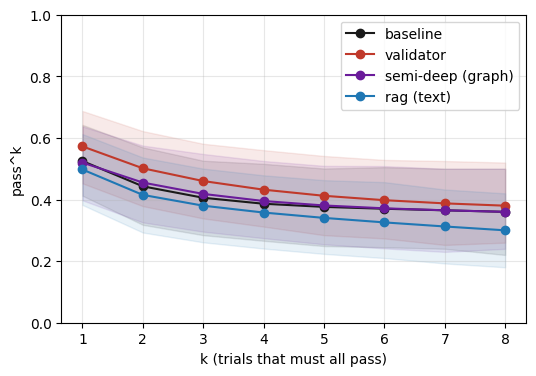

In [10]:
# Why: pass^k is the main metric (RQ1/RQ2). RAG is drawn with semi-deep so the two retrieval
# methods can be compared directly; a flatter curve (smaller drop) = a more consistent agent.
import os, csv
import matplotlib.pyplot as plt
import importlib, passk; importlib.reload(passk)
ARMS = [("baseline", "results_gemini_baseline", "#1A1A1A"),
        ("validator", "results_gemini_validator", "#C0392B"),
        ("semi-deep (graph)", "results_gemini_semideep", "#6A1B9A"),
        ("rag (text)", "results_gemini_rag", "#1F77B4")]
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS}
tab = pd.DataFrame([{"arm": name, **{f"k={r['k']}": round(r["pass^k"], 3) for r in rows},
                     "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}"}
                    for name, rows in curves.items() if rows])
show(tab)
rows = curves["rag (text)"]
if rows:
    with open(f"{ROOT}/results_gemini_rag_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
    plt.figure(figsize=(6, 4))
    for name, _, color in ARMS:
        r = curves[name]
        if not r: continue
        ks = [x["k"] for x in r]
        plt.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], alpha=0.10, color=color)
        plt.plot(ks, [x["pass^k"] for x in r], "o-", color=color, label=name)
    plt.xlabel("k (trials that must all pass)"); plt.ylabel("pass^k")
    plt.ylim(0, 1); plt.xticks(range(1, 9)); plt.grid(alpha=0.3); plt.legend()
    os.makedirs(f"{ROOT}/figures", exist_ok=True)
    plt.savefig(f"{ROOT}/figures/gemini_rag_passk.png", dpi=200, bbox_inches="tight")
    plt.show()

In [11]:
# Why: curves alone can differ by chance. A paired bootstrap over the SAME tasks says if a gap is
# real (* = 95% CI excludes 0). The key row is "vs semi-deep": graph retrieval vs text retrieval.
import random
from math import comb
import importlib, passk, violations as V; importlib.reload(passk); importlib.reload(V)
CLEAN = [t for t in range(N_TASKS) if t not in V.LABEL_CONFLICT]

def counts(d):
    tab = passk.table(f"{ROOT}/{d}")
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    return passk.success_counts(full, range(N_TASKS)), len(full)

C = {name: counts(d) for name, d in [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator"),
                                      ("semi-deep", "results_gemini_semideep"), ("rag", "results_gemini_rag")]}
assert all(n == N_TRIALS for _, n in C.values()), f"need 8 complete trials in every arm: { {k: n for k, (_, n) in C.items()} }"
C = {k: c for k, (c, _) in C.items()}

def delta(c_new, c_old, tasks, k, boot=2000, seed=0):
    f = lambda c, ts: sum(comb(c[t], k) / comb(N_TRIALS, k) for t in ts) / len(ts)
    est = f(c_new, tasks) - f(c_old, tasks)
    rng = random.Random(seed); s = []
    for _ in range(boot):
        pick = [rng.choice(tasks) for _ in tasks]
        s.append(f(c_new, pick) - f(c_old, pick))
    s.sort()
    lo, hi = s[int(0.025 * boot)], s[int(0.975 * boot) - 1]
    return f"{est:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "")

rows = [{"RAG vs": vs, "tasks": label, **{f"Δpass^{k}": delta(C["rag"], C[vs], tasks, k) for k in (1, 2, 4, 8)}}
        for vs in ["baseline", "validator", "semi-deep"]
        for label, tasks in [("all 50", list(range(N_TASKS))), ("clean 42", CLEAN)]]
show(pd.DataFrame(rows))
print("* = 95% CI does not include 0")
diff = pd.DataFrame([{"task": t, "semi-deep": C["semi-deep"][t], "rag": C["rag"][t]}
                     for t in range(N_TASKS) if C["rag"][t] != C["semi-deep"][t]])
print(f"tasks where RAG and semi-deep differ (passes out of 8): {len(diff)}")
if len(diff): show(diff)

RAG vs,tasks,Δpass^1,Δpass^2,Δpass^4,Δpass^8
baseline,all 50,"-0.028 [-0.088, +0.028]","-0.028 [-0.092, +0.031]","-0.029 [-0.093, +0.032]","-0.060 [-0.140, +0.020]"
baseline,clean 42,"+0.003 [-0.045, +0.051]","+0.006 [-0.040, +0.053]","+0.002 [-0.054, +0.056]","-0.048 [-0.143, +0.048]"
validator,all 50,"-0.075 [-0.138, -0.015] *","-0.086 [-0.157, -0.020] *","-0.074 [-0.154, -0.001] *","-0.080 [-0.180, +0.000]"
validator,clean 42,"-0.101 [-0.176, -0.033] *","-0.105 [-0.190, -0.023] *","-0.088 [-0.188, +0.001]","-0.095 [-0.214, +0.000]"
semi-deep,all 50,"-0.023 [-0.097, +0.050]","-0.040 [-0.119, +0.039]","-0.037 [-0.124, +0.047]","-0.060 [-0.160, +0.040]"
semi-deep,clean 42,"-0.036 [-0.122, +0.054]","-0.050 [-0.145, +0.047]","-0.045 [-0.146, +0.067]","-0.071 [-0.190, +0.048]"


* = 95% CI does not include 0
tasks where RAG and semi-deep differ (passes out of 8): 18


task,semi-deep,rag
0,4,7
1,8,7
3,1,2
5,4,2
6,5,1
7,0,2
14,3,1
15,6,8
17,5,4
20,8,7


In [12]:
# Why: pass^k only checks the final database. This counts rule-breaking write calls that really
# ran, to see if text retrieval stops violations as well as the graph does (semi-deep: 70 -> 2).
import importlib, violations as V, policy_checker as pc, passk
importlib.reload(V); importlib.reload(pc); importlib.reload(passk)
graph = pc.load_graph()
summary = []
for name, d in [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator"),
                ("semi-deep (graph)", "results_gemini_semideep"), ("rag (text)", "results_gemini_rag")]:
    rows, src, mism = V.count(passk.table(f"{ROOT}/{d}"), graph)
    df = pd.DataFrame(rows)
    if d == "results_gemini_rag":
        df.to_csv(f"{ROOT}/{d}_violations.csv", index=False)
        rag_src = dict(sorted((f"{s} {st}", c) for (s, st), c in src.items()))
    summary.append({"arm": name, "dialogues": len(df), "executed": int(df.executed.sum()),
                    "blocked": int(df.blocked.sum()),
                    "dialogues with ≥1": int(((df.executed + df.blocked) > 0).sum()),
                    "replay mismatches": mism})
show(pd.DataFrame(summary))
print("RAG violations by rule:", rag_src)

arm,dialogues,executed,blocked,dialogues with ≥1,replay mismatches
baseline,400,70,0,58,0
validator,400,0,69,63,0
semi-deep (graph),400,2,0,2,0
rag (text),400,28,0,25,0


RAG violations by rule: {'C2 executed': 3, 'C3 executed': 24, 'M2 executed': 1}


In [13]:
# Why: semi-deep failed mostly by being too careful (no call after the check). This shows whether
# RAG's rules make the agent more or less careful, per tool.
import glob, json
def decisions(d):
    return pd.DataFrame([json.loads(l) for f in sorted(glob.glob(f"{ROOT}/{d}/trial_*/checks.jsonl")) for l in open(f)])
parts = []
for name, d in [("semi-deep (graph)", "results_gemini_semideep"), ("rag (text)", "results_gemini_rag")]:
    df = decisions(d)
    if len(df):
        t = df["decision"].value_counts().reindex(["repeat", "other_tool", "no_call"], fill_value=0)
        parts.append({"arm": name, "checks": len(df), **t.to_dict(), "args changed": int(df.args_changed.sum())})
show(pd.DataFrame(parts))
df = decisions("results_gemini_rag")
if len(df):
    show(pd.crosstab(df["tool"], df["decision"], margins=True), index=True)

arm,checks,repeat,other_tool,no_call,args changed
semi-deep (graph),409,203,121,85,155
rag (text),440,313,32,95,201


decision,no_call,other_tool,repeat,All
tool,,,,
book_reservation,6,0,53,59
cancel_reservation,42,19,112,173
update_reservation_baggages,9,0,27,36
update_reservation_flights,35,8,111,154
update_reservation_passengers,3,5,10,18
All,95,32,313,440


In [14]:
# Why: if RAG does worse, is it because it RETRIEVED the wrong rules (retrieval failure) or because
# the agent misused the right ones (reasoning failure)? Recall vs the graph's bullets answers this.
import glob, json
df = pd.DataFrame([json.loads(l) for f in sorted(glob.glob(f"{ROOT}/results_gemini_rag/trial_*/rag.jsonl")) for l in open(f)])
if len(df):
    need = df["needed"].apply(set); got = df["sources"].apply(lambda s: {x for x in s if x})
    df["recall"] = [len(n & g) / len(n) for n, g in zip(need, got)]
    df["all found"] = [n <= g for n, g in zip(need, got)]
    df["missed"] = [", ".join(sorted(n - g)) for n, g in zip(need, got)]
    top = lambda s: s[s != ""].value_counts().index[0] if (s != "").any() else "-"
    out = df.groupby("tool").agg(retrievals=("recall", "size"), mean_recall=("recall", "mean"),
                                 all_found=("all found", "mean"), most_missed=("missed", top)).reset_index()
    out.loc[len(out)] = ["ALL", len(df), df.recall.mean(), df["all found"].mean(), top(df.missed)]
    out["mean_recall"] = out["mean_recall"].map("{:.0%}".format)
    out["all_found"] = out["all_found"].map("{:.0%}".format)
    show(out)

tool,retrievals,mean_recall,all_found,most_missed
book_reservation,59,43%,0%,"B1, B5, D3, G1"
cancel_reservation,173,79%,36%,C3
update_reservation_baggages,36,64%,0%,M1
update_reservation_flights,154,80%,5%,M3
update_reservation_passengers,18,33%,0%,"G1, M5"
ALL,440,71%,16%,M3


## Summary

**Setup:** same as semi-deep (08), but the rules come from vector search over `wiki.md` instead of the policy graph. Same timing, same prompt, same amount of text.

| | baseline | validator | semi-deep (graph) | RAG (text) |
|---|---|---|---|---|
| pass^1 | 0.525 | 0.573 | 0.520 | 0.497 |
| pass^8 | 0.360 | 0.380 | 0.360 | 0.300 |
| violations executed | 70 | 0 (69 blocked) | 2 | 28 |

- **Success:** RAG ≈ semi-deep. Δ on clean 42: pass^1 −0.036, pass^8 −0.071, both not significant.
- **Validator still wins (H1):** RAG − validator on clean 42: pass^1 −0.101*, pass^2 −0.105*.
- **Safety:** RAG lets through 28 violations vs 2 for semi-deep. 24 of the 28 break C3.
- **Why:** retrieval misses rules. Recall of the graph's bullets is 71%, and only 16% of checks got every needed rule. For cancel_reservation, the most missed rule is C3, the same rule behind most of the violations.
- **Behavior:** with fewer rules, the agent is bolder. It repeats the call more (313 vs 203) and looks things up less (32 vs 121).
- **Cost:** about $22 (token estimate). 0 API errors. 229 min.

**Takeaway:** the graph does not raise pass^k, but it keeps the agent inside the policy. Plain text retrieval misses rules, and a missed rule becomes a broken rule. In KiL terms, a retrieval failure turns into a process failure.